In [1]:
%pip install ucimlrepo pandas numpy matplotlib scikit-learn seaborn ipykernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from ucimlrepo import fetch_ucirepo

print("All required imports successful.")
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

All required imports successful.
pandas: 3.1.0
NumPy: 2.5.4
scikit-learn: 1.9.1


In [3]:
# Fetch the UCI Default of Credit Card Clients dataset using its unique ID.
credit_data = fetch_ucirepo(id=350)

# Separate predictor variables from the target we want to predict.
X = credit_data.data.features
y = credit_data.data.targets

# Display dimensions to verify the number of clients and variables.
print("Features:", X.shape)
print("Target:", y.shape)

# Display column names to understand what information is available.
print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget columns:")
print(y.columns.tolist())

Features: (30000, 23)
Target: (30000, 1)

Feature columns:
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']

Target columns:
['Y']


In [4]:
# Display UCI's original feature descriptions to map X1–X23
# to meaningful variable names before analysing the data.
print(credit_data.variables[
    ["name", "role", "type", "description"]
].to_string(index=False))

name    role    type                description
  ID      ID Integer                        NaN
  X1 Feature Integer                  LIMIT_BAL
  X2 Feature Integer                        SEX
  X3 Feature Integer                  EDUCATION
  X4 Feature Integer                   MARRIAGE
  X5 Feature Integer                        AGE
  X6 Feature Integer                      PAY_0
  X7 Feature Integer                      PAY_2
  X8 Feature Integer                      PAY_3
  X9 Feature Integer                      PAY_4
 X10 Feature Integer                      PAY_5
 X11 Feature Integer                      PAY_6
 X12 Feature Integer                  BILL_AMT1
 X13 Feature Integer                  BILL_AMT2
 X14 Feature Integer                  BILL_AMT3
 X15 Feature Integer                  BILL_AMT4
 X16 Feature Integer                  BILL_AMT5
 X17 Feature Integer                  BILL_AMT6
 X18 Feature Integer                   PAY_AMT1
 X19 Feature Integer                   P

In [5]:
# Check the target's class counts to understand how many clients
# defaulted versus did not default.
print("Target distribution:")
print(y["Y"].value_counts().sort_index())

# Check target proportions to measure class imbalance.
print("\nTarget proportions:")
print(y["Y"].value_counts(normalize=True).sort_index().round(4))

# Inspect the first five observations to see how the encoded data looks.
print("\nFirst five observations:")
display(X.head())

Target distribution:
Y
0    23364
1     6636
Name: count, dtype: int64

Target proportions:
Y
0    0.7788
1    0.2212
Name: proportion, dtype: float64

First five observations:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [6]:
# Display five records to inspect the values and structure of the predictors.
display(X.head())

# Check data types and non-null counts to identify potential data-quality issues.
X.info()

# Check whether the UCI package includes an ID column in the feature data.
print("\nID column present:", "ID" in X.columns)

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-null  int64
 2   X3      30000 non-null  int64
 3   X4      30000 non-null  int64
 4   X5      30000 non-null  int64
 5   X6      30000 non-null  int64
 6   X7      30000 non-null  int64
 7   X8      30000 non-null  int64
 8   X9      30000 non-null  int64
 9   X10     30000 non-null  int64
 10  X11     30000 non-null  int64
 11  X12     30000 non-null  int64
 12  X13     30000 non-null  int64
 13  X14     30000 non-null  int64
 14  X15     30000 non-null  int64
 15  X16     30000 non-null  int64
 16  X17     30000 non-null  int64
 17  X18     30000 non-null  int64
 18  X19     30000 non-null  int64
 19  X20     30000 non-null  int64
 20  X21     30000 non-null  int64
 21  X22     30000 non-null  int64
 22  X23     30000 non-null  int64
dtypes: int64(23)
memory us

In [7]:
# Check column data types and non-null counts for data-quality issues.
X.info()

# Verify whether the imported features contain the original client ID.
print("\nID column present:", "ID" in X.columns)

# Check for duplicate rows in the feature data.
print("\nDuplicate feature rows:", X.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-null  int64
 2   X3      30000 non-null  int64
 3   X4      30000 non-null  int64
 4   X5      30000 non-null  int64
 5   X6      30000 non-null  int64
 6   X7      30000 non-null  int64
 7   X8      30000 non-null  int64
 8   X9      30000 non-null  int64
 9   X10     30000 non-null  int64
 10  X11     30000 non-null  int64
 11  X12     30000 non-null  int64
 12  X13     30000 non-null  int64
 13  X14     30000 non-null  int64
 14  X15     30000 non-null  int64
 15  X16     30000 non-null  int64
 16  X17     30000 non-null  int64
 17  X18     30000 non-null  int64
 18  X19     30000 non-null  int64
 19  X20     30000 non-null  int64
 20  X21     30000 non-null  int64
 21  X22     30000 non-null  int64
 22  X23     30000 non-null  int64
dtypes: int64(23)
memory us

In [8]:
# Inspect all metadata fields to understand how UCI represents the ID column.
display(credit_data.variables)

# Count rows with identical feature values, including repeated occurrences.
print("Duplicate feature rows:", X.duplicated().sum())

# Inspect repeated feature combinations to determine whether they are exact matches.
display(X[X.duplicated(keep=False)].head(10))

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,NaN,NaN,None,no
1,X1,Feature,Integer,NaN,LIMIT_BAL,None,no
2,X2,Feature,Integer,Sex,SEX,None,no
3,X3,Feature,Integer,Education Level,EDUCATION,None,no
4,X4,Feature,Integer,Marital Status,MARRIAGE,None,no
5,X5,Feature,Integer,Age,AGE,None,no
6,X6,Feature,Integer,NaN,PAY_0,None,no
7,X7,Feature,Integer,NaN,PAY_2,None,no
8,X8,Feature,Integer,NaN,PAY_3,None,no
9,X9,Feature,Integer,NaN,PAY_4,None,no


Duplicate feature rows: 56


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
18,360000,2,1,1,49,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
291,50000,2,2,2,22,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
627,230000,1,1,1,39,-1,-1,-1,-1,-1,...,660,660,660,660,660,660,660,660,660,660
839,500000,1,1,1,43,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
881,210000,2,2,1,49,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1093,360000,1,2,1,41,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1211,160000,2,3,2,26,-1,-1,-1,-1,-1,...,390,390,390,390,390,390,390,390,390,390
1601,150000,2,1,1,31,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1759,50000,1,2,2,26,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1964,150000,2,1,1,38,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0


In [9]:
# Combine predictors and target so duplicate records can be compared by outcome.
data = X.join(y)

# Count exact duplicate records, including the target.
print("Exact duplicate records:", data.duplicated().sum())

# Count repeated feature combinations that have different target values.
target_counts = data.groupby(list(X.columns))["Y"].nunique()
print("Feature combinations with conflicting targets:", (target_counts > 1).sum())

Exact duplicate records: 35
Feature combinations with conflicting targets: 21


In [10]:
# Display the UCI metadata to inspect the ID and target definitions.
display(credit_data.variables.to_string(index=False))

# Check the dataset's descriptive metadata for source and citation details.
print("Dataset metadata:")
print(credit_data.metadata)

'name    role    type     demographic                description units missing_values\n  ID      ID Integer             NaN                        NaN  None             no\n  X1 Feature Integer             NaN                  LIMIT_BAL  None             no\n  X2 Feature Integer             Sex                        SEX  None             no\n  X3 Feature Integer Education Level                  EDUCATION  None             no\n  X4 Feature Integer  Marital Status                   MARRIAGE  None             no\n  X5 Feature Integer             Age                        AGE  None             no\n  X6 Feature Integer             NaN                      PAY_0  None             no\n  X7 Feature Integer             NaN                      PAY_2  None             no\n  X8 Feature Integer             NaN                      PAY_3  None             no\n  X9 Feature Integer             NaN                      PAY_4  None             no\n X10 Feature Integer             NaN                 

Dataset metadata:
{'uci_id': 350, 'name': 'Default of Credit Card Clients', 'repository_url': 'https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients', 'data_url': 'https://archive.ics.uci.edu/static/public/350/data.csv', 'abstract': "This research aimed at the case of customers' default payments in Taiwan and compares the predictive accuracy of probability of default among six data mining methods.", 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 30000, 'num_features': 23, 'feature_types': ['Integer', 'Real'], 'demographics': ['Sex', 'Education Level', 'Marital Status', 'Age'], 'target_col': ['Y'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Fri Mar 29 2024', 'dataset_doi': '10.24432/C55S3H', 'creators': ['I-Cheng Yeh'], 'intro_paper': {'ID': 365, 'type': 'NATIVE', 'title': 'The comparisons of data mining techniques for the predi

Phase 1 — Step 1: Create the working DataFrame

In [11]:
# Combine predictors and target into one DataFrame for data-quality checks.
# join() aligns rows by index, keeping each client's features with its outcome.
df = X.join(y)

# Confirm the number of rows and columns before further analysis.
print("Dataset shape:", df.shape)

# Count missing cells across all columns to check data completeness.
print("Total missing values:", df.isnull().sum().sum())

# Count fully duplicated records, including the target.
print("Exact duplicate records:", df.duplicated().sum())


Dataset shape: (30000, 24)
Total missing values: 0
Exact duplicate records: 35


In [12]:
# Display the range of values in each column to identify unusual codes or values.
display(df.describe().T)

# Inspect the distinct values in repayment-status columns.
# These columns use categorical codes, so unexpected values need investigation.
pay_cols = ["X6", "X7", "X8", "X9", "X10", "X11"]

for col in pay_cols:
    print(f"{col}: {sorted(df[col].unique())}")
    

,count,mean,std,min,25%,50%,75%,max
X1,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
X2,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
X3,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
X4,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
X5,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
X6,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
X7,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
X8,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
X9,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
X10,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


X6: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
X7: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
X8: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
X9: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
X10: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
X11: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]


In [13]:
# Inspect distinct codes in demographic variables to identify unexpected categories.
for col in ["X2", "X3", "X4"]:
    print(f"{col}: {sorted(df[col].unique())}")

# Count observations for each repayment-status code in the latest month.
# X6 represents repayment status in September 2005.
print("\nLatest repayment-status counts:")
print(df["X6"].value_counts().sort_index())

X2: [np.int64(1), np.int64(2)]
X3: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
X4: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Latest repayment-status counts:
X6
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


In [14]:
# Count undocumented education and marital-status codes.
# This measures how many records need a documented cleaning decision.
for col in ["X3", "X4"]:
    print(f"\n{col} value counts:")
    print(df[col].value_counts().sort_index())

# Count the undocumented repayment-status codes across all six months.
# This helps us assess their prevalence before deciding how to handle them.
pay_cols = ["X6", "X7", "X8", "X9", "X10", "X11"]

for col in pay_cols:
    print(f"\n{col}:")
    print(df[col].value_counts().reindex([-2, 0], fill_value=0))




X3 value counts:
X3
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

X4 value counts:
X4
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

X6:
X6
-2     2759
 0    14737
Name: count, dtype: int64

X7:
X7
-2     3782
 0    15730
Name: count, dtype: int64

X8:
X8
-2     4085
 0    15764
Name: count, dtype: int64

X9:
X9
-2     4348
 0    16455
Name: count, dtype: int64

X10:
X10
-2     4546
 0    16947
Name: count, dtype: int64

X11:
X11
-2     4895
 0    16286
Name: count, dtype: int64


In [15]:

# Print the original descriptions of education, marital status, and repayment history.
# This lets us compare the documented categories with the codes actually observed.
print(credit_data.metadata["additional_info"]["variable_info"])

This research employed a binary variable, default payment (Yes = 1, No = 0), as the response variable. This study reviewed the literature and used the following 23 variables as explanatory variables:
X1: Amount of the given credit (NT dollar): it includes both the individual consumer credit and his/her family (supplementary) credit.
X2: Gender (1 = male; 2 = female).
X3: Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).
X4: Marital status (1 = married; 2 = single; 3 = others).
X5: Age (year).
X6 - X11: History of past payment. We tracked the past monthly payment records (from April to September, 2005) as follows: X6 = the repayment status in September, 2005; X7 = the repayment status in August, 2005; . . .;X11 = the repayment status in April, 2005. The measurement scale for the repayment status is: -1 = pay duly; 1 = payment delay for one month; 2 = payment delay for two months; . . .; 8 = payment delay for eight months; 9 = payment delay for nine months and

In [16]:
# Count education and marital-status codes not listed in the original documentation.
# This quantifies how many observations require further investigation.
for col, documented_codes in {"X3": [1, 2, 3, 4], "X4": [1, 2, 3]}.items():
    undocumented = df.loc[~df[col].isin(documented_codes), col]

    # Show the frequency of each undocumented code.
    print(f"\n{col} — undocumented codes:")
    print(undocumented.value_counts().sort_index())


X3 — undocumented codes:
X3
0     14
5    280
6     51
Name: count, dtype: int64

X4 — undocumented codes:
X4
0    54
Name: count, dtype: int64


In [17]:
# Count undocumented repayment-status codes across all six months.
# This shows how frequently -2 and 0 occur before we decide how to interpret them.
for col in ["X6", "X7", "X8", "X9", "X10", "X11"]:
    print(f"\n{col}:")
    print(df[col].value_counts().sort_index().loc[lambda s: s.index.isin([-2, 0])])


X6:
X6
-2     2759
 0    14737
Name: count, dtype: int64

X7:
X7
-2     3782
 0    15730
Name: count, dtype: int64

X8:
X8
-2     4085
 0    15764
Name: count, dtype: int64

X9:
X9
-2     4348
 0    16455
Name: count, dtype: int64

X10:
X10
-2     4546
 0    16947
Name: count, dtype: int64

X11:
X11
-2     4895
 0    16286
Name: count, dtype: int64


In [18]:
# Display the original repayment-status definitions from the dataset metadata.
# We need the source's exact wording before deciding how to interpret -2 and 0.
print(credit_data.metadata["additional_info"]["variable_info"])

This research employed a binary variable, default payment (Yes = 1, No = 0), as the response variable. This study reviewed the literature and used the following 23 variables as explanatory variables:
X1: Amount of the given credit (NT dollar): it includes both the individual consumer credit and his/her family (supplementary) credit.
X2: Gender (1 = male; 2 = female).
X3: Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).
X4: Marital status (1 = married; 2 = single; 3 = others).
X5: Age (year).
X6 - X11: History of past payment. We tracked the past monthly payment records (from April to September, 2005) as follows: X6 = the repayment status in September, 2005; X7 = the repayment status in August, 2005; . . .;X11 = the repayment status in April, 2005. The measurement scale for the repayment status is: -1 = pay duly; 1 = payment delay for one month; 2 = payment delay for two months; . . .; 8 = payment delay for eight months; 9 = payment delay for nine months and

In [19]:
# Replace generic X1–X23 labels with meaningful names.
# This improves readability without changing any values or observations.
column_names = {
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    **{f"X{i}": f"BILL_AMT{i-11}" for i in range(12, 18)},
    **{f"X{i}": f"PAY_AMT{i-17}" for i in range(18, 24)},
}

# Rename columns in place; retain the target column Y.
df.rename(columns=column_names, inplace=True)

# Verify the resulting column names.
print(df.columns.tolist())

['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'Y']


C:\Users\upscc\AppData\Local\Temp\ipykernel_20708\3203959406.py:20: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns=column_names, inplace=True)


Phase 2 — Data cleaning and exploratory analysis

In [20]:
# Count fully duplicated rows, including the target Y.
# This establishes how many records are exact copies before any removal.
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 35


In [21]:
# Find feature combinations associated with more than one target value.
# This checks whether identical predictors ever correspond to different default outcomes.
feature_cols = df.drop(columns="Y").columns

target_counts = df.groupby(list(feature_cols))["Y"].nunique()
print("Feature combinations with conflicting targets:", (target_counts > 1).sum())

Feature combinations with conflicting targets: 21


In [22]:
# Identify feature combinations that appear with both target outcomes.
# Inspect their target counts before deciding whether any records need removal.
conflicting_features = target_counts[target_counts > 1].index

conflicts = (
    df.set_index(list(feature_cols))
      .loc[conflicting_features]
      .reset_index()
      .groupby(list(feature_cols) + ["Y"])
      .size()
      .rename("row_count")
      .reset_index()
)

print(conflicts[["Y", "row_count"]].to_string(index=False))

 Y  row_count
 0          1
 1          2
 0          1
 1          1
 0          1
 1          1
 0          1
 1          1
 0          1
 1          1
 0          1
 1          1
 0          1
 1          1
 0          1
 1          1
 0          1
 1          1
 0          1
 1          1
 0          2
 1          1
 0          1
 1          1
 0          1
 1          1
 0          2
 1          1
 0          1
 1          1
 0          1
 1          1
 0          1
 1          1
 0          1
 1          1
 0          2
 1          1
 0          1
 1          1
 0          1
 1          1


In [23]:
# Summarize how many rows belong to conflicting feature combinations.
# This gives us a compact result without overwhelming notebook output.
conflict_summary = (
    df.groupby(list(feature_cols))["Y"]
      .agg(rows="size", distinct_targets="nunique")
)

print("Conflicting feature combinations:", (conflict_summary["distinct_targets"] > 1).sum())
print("Rows in conflicting combinations:", conflict_summary.loc[conflict_summary["distinct_targets"] > 1, "rows"].sum())
print("\nDistribution of row counts:")
print(conflict_summary.loc[conflict_summary["distinct_targets"] > 1, "rows"].value_counts().sort_index())

Conflicting feature combinations: 21
Rows in conflicting combinations: 46

Distribution of row counts:
rows
2    17
3     4
Name: count, dtype: int64


In [24]:
# Count exact duplicate rows separately for each target outcome.
# This checks whether the 35 duplicates are concentrated in either target class.
print(
    df.loc[df.duplicated(keep=False)]
      .groupby("Y")
      .size()
)

Y
0    58
1    12
dtype: int64


In [25]:
# Remove exact duplicate rows while retaining the first occurrence.
# Identical predictors and target values provide no new information.
df = df.drop_duplicates().reset_index(drop=True)

# Verify the cleaned row count and confirm exact duplicates are gone.
print("Shape after removing exact duplicates:", df.shape)
print("Remaining exact duplicates:", df.duplicated().sum())

Shape after removing exact duplicates: (29965, 24)
Remaining exact duplicates: 0


In [26]:
# Check missing values, target counts, and data types after deduplication.
# These checks confirm the dataset is structurally ready for EDA.
print("Missing values:", df.isna().sum().sum())
print("\nTarget distribution:")
print(df["Y"].value_counts().sort_index())
print("\nData types:")
print(df.dtypes.value_counts())

Missing values: 0

Target distribution:
Y
0    23335
1     6630
Name: count, dtype: int64

Data types:
int64    24
Name: count, dtype: int64


In [27]:
# Summarize the range of each variable after deduplication.
# Minimums and maximums help identify unusual values before EDA.
print(df.describe().T[["min", "max"]].to_string())

                min        max
LIMIT_BAL   10000.0  1000000.0
SEX             1.0        2.0
EDUCATION       0.0        6.0
MARRIAGE        0.0        3.0
AGE            21.0       79.0
PAY_0          -2.0        8.0
PAY_2          -2.0        8.0
PAY_3          -2.0        8.0
PAY_4          -2.0        8.0
PAY_5          -2.0        8.0
PAY_6          -2.0        8.0
BILL_AMT1 -165580.0   964511.0
BILL_AMT2  -69777.0   983931.0
BILL_AMT3 -157264.0  1664089.0
BILL_AMT4 -170000.0   891586.0
BILL_AMT5  -81334.0   927171.0
BILL_AMT6 -339603.0   961664.0
PAY_AMT1        0.0   873552.0
PAY_AMT2        0.0  1684259.0
PAY_AMT3        0.0   896040.0
PAY_AMT4        0.0   621000.0
PAY_AMT5        0.0   426529.0
PAY_AMT6        0.0   528666.0
Y               0.0        1.0


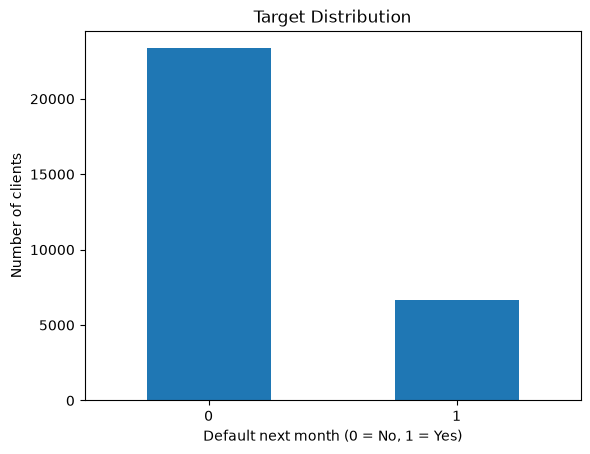

In [28]:
# Plot the number of clients in each target class.
# This visualizes class imbalance before we choose evaluation metrics.
df["Y"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Number of clients")
plt.title("Target Distribution")
plt.xticks(rotation=0)
plt.show()

In [29]:
# Calculate the percentage of clients in each target class.
# Percentages quantify the imbalance shown in the bar chart.
print((df["Y"].value_counts(normalize=True).sort_index() * 100).round(2))

Y
0    77.87
1    22.13
Name: proportion, dtype: float64


In [30]:
# Calculate the next-month default rate for each latest repayment-status code.
# This tests whether recent repayment behaviour is associated with future default.
default_by_status = df.groupby("PAY_0")["Y"].mean() * 100

print(default_by_status.round(2))

PAY_0
-2    13.24
-1    16.79
 0    12.81
 1    34.03
 2    69.13
 3    75.78
 4    68.42
 5    50.00
 6    54.55
 7    77.78
 8    57.89
Name: Y, dtype: float64


In [31]:
# Count clients in each latest repayment-status category.
# Small groups can produce unstable default-rate estimates.
print(df["PAY_0"].value_counts().sort_index())

PAY_0
-2     2750
-1     5682
 0    14737
 1     3667
 2     2666
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


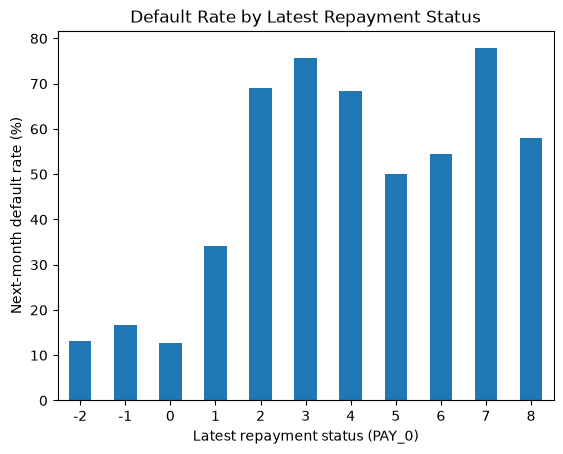

In [32]:
# Calculate and plot default rates by latest repayment status.
# The chart makes the relationship easier to compare across categories.
default_by_status = df.groupby("PAY_0")["Y"].mean() * 100

default_by_status.plot(kind="bar")
plt.xlabel("Latest repayment status (PAY_0)")
plt.ylabel("Next-month default rate (%)")
plt.title("Default Rate by Latest Repayment Status")
plt.xticks(rotation=0)
plt.show()

In [33]:
# Divide credit limits into five equal-width ranges and calculate default rates.
# This checks whether observed default rates differ across credit-limit levels.
df["credit_limit_bucket"] = pd.cut(df["LIMIT_BAL"], bins=5)

default_by_limit = df.groupby("credit_limit_bucket", observed=False)["Y"].mean() * 100
print(default_by_limit.round(2))

credit_limit_bucket
(9010.0, 208000.0]       25.63
(208000.0, 406000.0]     15.34
(406000.0, 604000.0]     12.18
(604000.0, 802000.0]      7.69
(802000.0, 1000000.0]     0.00
Name: Y, dtype: float64


In [34]:
# Counting clients in each credit-limit range
# To assess how reliable each bucket's default rate is
print(df.groupby("credit_limit_bucket", observed=False)["Y"].agg(
    clients="size",
    defaults="sum",
    default_rate=lambda x: round(x.mean() * 100, 2)
))

                       clients  defaults  default_rate
credit_limit_bucket                                   
(9010.0, 208000.0]       20357      5217         25.63
(208000.0, 406000.0]      7805      1197         15.34
(406000.0, 604000.0]      1724       210         12.18
(604000.0, 802000.0]        78         6          7.69
(802000.0, 1000000.0]        1         0          0.00


In [35]:
# Comparing average bill amounts for default and non-default clients
# To examine whether outstanding statement balances differ by outcome
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]

print(df.groupby("Y")[bill_cols].mean().round(2).T)

Y                 0         1
BILL_AMT1  52058.72  48552.81
BILL_AMT2  49779.10  47326.16
BILL_AMT3  47592.31  45222.24
BILL_AMT4  43665.24  42074.74
BILL_AMT5  40580.69  39575.72
BILL_AMT6  39090.67  38305.82


In [36]:
# Comparing average payment amounts for default and non-default clients
# To examine whether payment behaviour differs by next-month default outcome
pay_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

print(df.groupby("Y")[pay_cols].mean().round(2).T)

Y               0        1
PAY_AMT1  6315.05  3400.12
PAY_AMT2  6648.59  3391.72
PAY_AMT3  5760.52  3370.40
PAY_AMT4  5306.99  3158.48
PAY_AMT5  5254.62  3222.05
PAY_AMT6  5726.36  3444.60


In [37]:
# Counting months with positive repayment delays for each client
# To compare next-month default rates by accumulated payment delays
pay_status_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
df["number_of_months_with_delay"] = (df[pay_status_cols] > 0).sum(axis=1)

print(
    df.groupby("number_of_months_with_delay")["Y"]
      .agg(clients="size", default_rate=lambda x: round(x.mean() * 100, 2))
)

                             clients  default_rate
number_of_months_with_delay                       
0                              19918         11.71
1                               4405         29.88
2                               1899         38.76
3                               1154         50.87
4                                951         57.31
5                                298         57.38
6                               1340         70.30


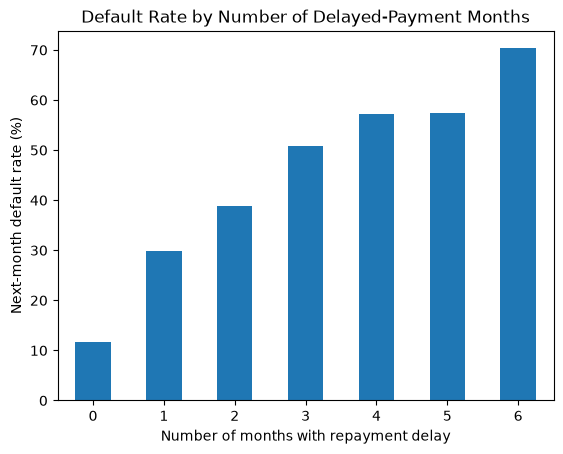

In [38]:
# Plotting default rates by the number of delayed-payment months
# To visualize how repeated delays relate to next-month default
default_by_delay = df.groupby("number_of_months_with_delay")["Y"].mean() * 100

default_by_delay.plot(kind="bar")
plt.xlabel("Number of months with repayment delay")
plt.ylabel("Next-month default rate (%)")
plt.title("Default Rate by Number of Delayed-Payment Months")
plt.xticks(rotation=0)
plt.show()

In [39]:
# Selecting credit limits, bill amounts, and payment amounts
# To examine correlations among the dataset's financial variables
financial_cols = (
    ["LIMIT_BAL"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)

correlation_matrix = df[financial_cols].corr()

print(correlation_matrix.round(2))

           LIMIT_BAL  BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  BILL_AMT5  \
LIMIT_BAL       1.00       0.29       0.28       0.28       0.29       0.30   
BILL_AMT1       0.29       1.00       0.95       0.89       0.86       0.83   
BILL_AMT2       0.28       0.95       1.00       0.93       0.89       0.86   
BILL_AMT3       0.28       0.89       0.93       1.00       0.92       0.88   
BILL_AMT4       0.29       0.86       0.89       0.92       1.00       0.94   
BILL_AMT5       0.30       0.83       0.86       0.88       0.94       1.00   
BILL_AMT6       0.29       0.80       0.83       0.85       0.90       0.95   
PAY_AMT1        0.20       0.14       0.28       0.24       0.23       0.22   
PAY_AMT2        0.18       0.10       0.10       0.32       0.21       0.18   
PAY_AMT3        0.21       0.16       0.15       0.13       0.30       0.25   
PAY_AMT4        0.20       0.16       0.15       0.14       0.13       0.29   
PAY_AMT5        0.22       0.17       0.16       0.1

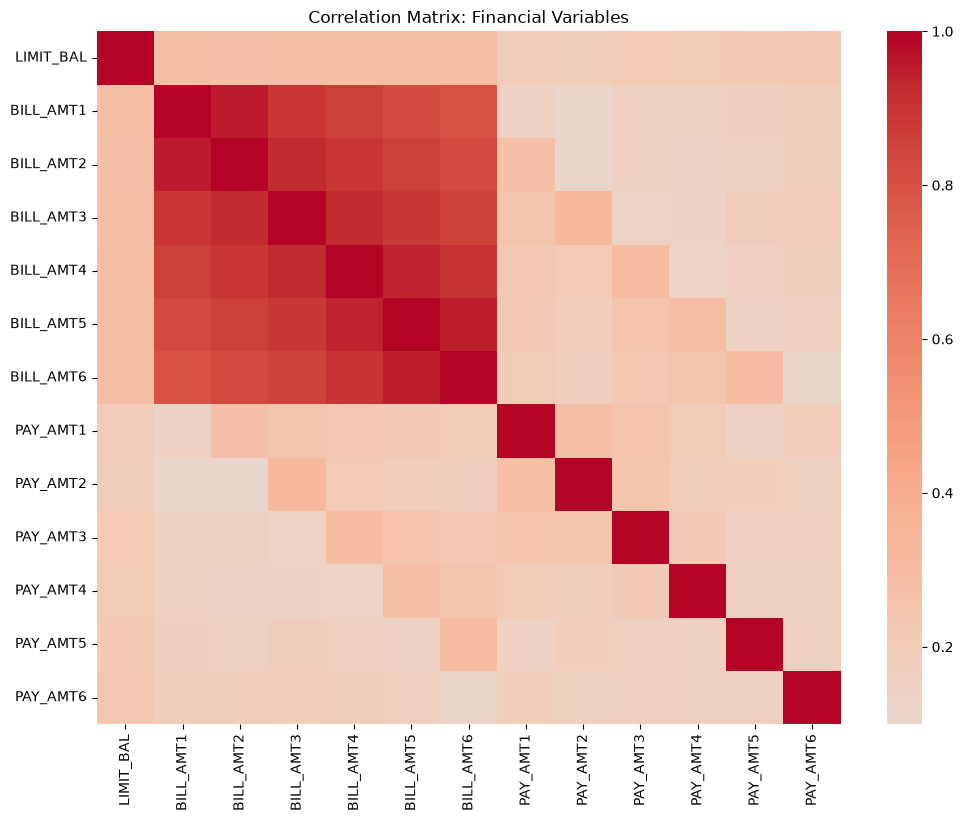

In [40]:
# Creating a heatmap of correlations among financial variables
# To identify strong relationships and overlapping information visually
import seaborn as sns

plt.figure(figsize=(12, 9))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Matrix: Financial Variables")
plt.show()

In [41]:
# Comparing default rates across education and marital-status categories
# To examine outcome differences for the limited demographic audit
print("Education:")
print((df.groupby("EDUCATION")["Y"].mean() * 100).round(2))

print("\nMarital status:")
print((df.groupby("MARRIAGE")["Y"].mean() * 100).round(2))

Education:
EDUCATION
0     0.00
1    19.24
2    23.74
3    25.17
4     5.69
5     6.43
6    15.69
Name: Y, dtype: float64

Marital status:
MARRIAGE
0     9.26
1    23.46
2    20.95
3    26.01
Name: Y, dtype: float64


In [42]:
# Counting clients in each education and marital-status category
# To assess the reliability of the category-level default rates
print("Education:")
print(df["EDUCATION"].value_counts().sort_index())

print("\nMarital status:")
print(df["MARRIAGE"].value_counts().sort_index())

Education:
EDUCATION
0       14
1    10563
2    14019
3     4915
4      123
5      280
6       51
Name: count, dtype: int64

Marital status:
MARRIAGE
0       54
1    13643
2    15945
3      323
Name: count, dtype: int64


In [43]:
# Comparing default rates across sex categories
# To examine outcome differences for the limited demographic audit
print("Client counts:")
print(df["SEX"].value_counts().sort_index())

print("\nDefault rates (%):")
print((df.groupby("SEX")["Y"].mean() * 100).round(2))

Client counts:
SEX
1    11874
2    18091
Name: count, dtype: int64

Default rates (%):
SEX
1    24.16
2    20.79
Name: Y, dtype: float64


Phase 1 — EDA progress
We have examined:
- Target distribution and class imbalance
- Default rates by latest repayment status
- Default rates by credit-limit bucket
- Average bill and payment amounts by outcome
- Number of delayed-payment months versus default
- Correlations among financial variables
- Outcome differences by education, marital status, and sex
Next: We should check age bands, then consolidate the findings and review the remaining Phase 1 requirements before moving to feature engineering.

In [44]:

# Grouping clients into age bands
# To compare next-month default rates across age groups
df["age_band"] = pd.cut(
    df["AGE"],
    bins=[20, 30, 40, 50, 60, 80],
    labels=["21–30", "31–40", "41–50", "51–60", "61–79"]
)

print(
    df.groupby("age_band", observed=False)["Y"]
      .agg(
          clients="size",
          default_rate=lambda x: round(x.mean() * 100, 2)
      )
)

          clients  default_rate
age_band                       
21–30       10997         22.46
31–40       10702         20.44
41–50        5997         23.26
51–60        1997         25.24
61–79         272         26.84


Phase 1 — EDA summary
We have now completed the planned EDA comparisons. Before moving to feature engineering, let's save the key findings in the project documentation.
Findings to record
- Target imbalance: 22.13% default versus 77.87% non-default.
- Repayment history: Higher recent delay codes and more months with delays are associated with higher default rates.
- Credit limits: Default rates generally decline across the well-populated credit-limit buckets; the highest bucket has only one client.
- Bill amounts: Average bills are slightly lower among defaulting clients.
- Payment amounts: Average payments are consistently lower among defaulting clients.
- Correlations: Bill amounts are strongly correlated across months.
- Demographic audit: Default rates differ across sex, education, marital-status, and age groups. These variables are not automatically suitable predictors.

In [45]:
# Checking the current dataset dimensions and column names
# To confirm which original and EDA columns are present before saving Phase 1
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (29965, 27)

Columns:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'Y', 'credit_limit_bucket', 'number_of_months_with_delay', 'age_band']


Next step: Create the clean dataset

In [46]:
# Selecting the original dataset columns after duplicate removal
# To keep EDA helper columns out of the cleaned source dataset
original_cols = column_names.values()
clean_df = df[list(original_cols) + ["Y"]].copy()

# Verifying the cleaned dataset structure
print("Shape:", clean_df.shape)
print("Exact duplicates:", clean_df.duplicated().sum())
print("Missing values:", clean_df.isna().sum().sum())

Shape: (29965, 24)
Exact duplicates: 0
Missing values: 0


In [48]:
# Creating the output directory if it does not exist
# To ensure the cleaned CSV has a valid destination
from pathlib import Path

output_path = Path("../data/processed/credit_default_clean.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

# Saving the cleaned dataset without an extra index column
clean_df.to_csv(output_path, index=False)

print("Saved to:", output_path.resolve())

Saved to: D:\PYTHON\projects\credit-risk-decision-support\data\processed\credit_default_clean.csv
